# 01 · Data exploration — understanding the AUV hull dataset

**Goal of this notebook:** *look* at the data before building more models. We want to understand what the hulls are,
what ranges they cover, and where (and why) prediction models fail.

**The dataset** comes from Vardhan et al. (2023). Someone designed 3,021 torpedo-shaped underwater-vehicle hulls,
ran a CFD (computational fluid dynamics) simulation on each one, and recorded the **drag force** — how hard the water
pushes back when the hull moves forward at 2 m/s.

**Sections** (we do them one at a time):
1. **The design space** ← *we are here*
2. Hull gallery — drawing the shapes
3. Physics view — friction vs shape effects
4. Error maps — where each model fails
5. The one CFD case we have
6. Data quality — duplicates, outliers, noise

> **How to use this notebook:** run each cell in order with **Shift + Enter**. Read the text above each cell first —
> it explains what the code does and what to look for in the result.

---
## Section 1 · The design space

### 1.1 What describes a hull?
Each hull is a **Myring hull**: a rounded nose, a straight cylinder in the middle, and a tapering tail.
Six numbers fully describe its shape:

| Symbol | Meaning | Unit |
|---|---|---|
| `a` | nose length | mm |
| `b` | length of the straight middle part | mm |
| `c` | tail length | mm |
| `d` | diameter (thickest width of the hull) | mm |
| `n` | nose "fullness" — small *n* = pointed nose, large *n* = blunt, rounded nose | no unit |
| `θ` (theta) | tail angle at the very end — large θ = abrupt, steep tail | degrees |

And one result per hull:

| Symbol | Meaning | Unit |
|---|---|---|
| `D` | drag force from the CFD simulation | newtons (N) |

### 1.2 Load the data
The data is two plain text files, one row per hull, seven numbers per row (`a b c d n θ D`).
- **train** (2,400 hulls): the examples models are allowed to *learn* from.
- **test** (621 hulls): kept aside to *check* models fairly — like an exam they have never seen.

In [1]:
# numpy: the standard Python library for working with arrays (tables) of numbers
import numpy as np

# Where the original authors' data lives (a read-only copy in our project folder)
DATA = '../reference/UUV-design-optimization/'
train = np.loadtxt(DATA + 'cad_cfd_pipeline_surrogate_data_generation/surrogate_data/train_2400.txt')
test  = np.loadtxt(DATA + 'uuv_optim/data/surrogate/test_data.txt')

# .shape tells us (number of rows, number of columns)
print('train:', train.shape, '  test:', test.shape)

# Show the first 3 hulls of the training set so we can see what a row looks like
print('\n   a(mm)   b(mm)   c(mm)   d(mm)    n     θ(°)   D(N)')
for row in train[:3]:
    print('  '.join(f'{v:6.1f}' for v in row))

train: (2400, 7)   test: (621, 7)

   a(mm)   b(mm)   c(mm)   d(mm)    n     θ(°)   D(N)
 253.2   561.5   292.8   107.5     3.1    49.3     3.8
 243.0   853.9   386.5   141.0     3.6    35.4     5.4
 304.9   472.5   385.0   167.8     3.9    14.2     5.1


### 1.3 Give the columns names and compute a few useful extra quantities
Working with `train[:, 3]` ("column 3 of train") is hard to read, so we give each column a name.

We also compute two **derived** quantities that engineers care about:
- **Total length** `L = a + b + c`
- **Fineness ratio** `L/d` = length ÷ diameter. It says how *slender* a hull is:
  - **L/d ≈ 5** → short and fat (like a rugby ball) — water struggles to flow smoothly around the back
  - **L/d ≈ 8–10** → typical real AUVs (e.g. the REMUS-100)
  - **L/d ≈ 20+** → very long and thin (like a pencil)

In [2]:
def columns(data):
    """Split a data table into named columns and add derived quantities. Returns a dictionary."""
    a, b, c, d, n, theta, D = data.T          # .T = transpose: turn the 7 columns into 7 separate arrays
    L = a + b + c                              # total length (mm)
    return dict(a=a, b=b, c=c, d=d, n=n, theta=theta, D=D, L=L, Ld=L / d)

tr = columns(train)
te = columns(test)

# Example: the fineness ratio of the first 5 training hulls
print('L/d of the first 5 training hulls:', np.round(tr['Ld'][:5], 1))

L/d of the first 5 training hulls: [10.3 10.5  6.9 14.2 11.8]


### 1.4 What ranges do the numbers cover?
For each quantity we print the **minimum**, **median** (the middle value: half the hulls are below it) and
**maximum**, for both train and test. If the two sets cover similar ranges, the test is a fair check of the same
"design space".

In [3]:
names = {'a': 'nose length a (mm)', 'b': 'middle length b (mm)', 'c': 'tail length c (mm)',
         'd': 'diameter d (mm)', 'n': 'nose shape n', 'theta': 'tail angle θ (°)',
         'L': 'total length L (mm)', 'Ld': 'fineness L/d', 'D': 'drag D (N)'}

print(f'{"quantity":24s} | {"train: min  median   max":>27s} | {"test: min  median   max":>26s}')
print('-' * 84)
for key, label in names.items():
    t, s = tr[key], te[key]
    print(f'{label:24s} | {t.min():8.1f} {np.median(t):8.1f} {t.max():8.1f} | '
          f'{s.min():8.1f} {np.median(s):8.1f} {s.max():8.1f}')

quantity                 |    train: min  median   max |    test: min  median   max
------------------------------------------------------------------------------------
nose length a (mm)       |     53.2    238.7    584.0 |     53.5    250.3    596.8
middle length b (mm)     |     16.4    982.7   1805.6 |      1.4    982.9   1827.2
tail length c (mm)       |     53.3    240.4    592.5 |     54.6    241.5    585.4
diameter d (mm)          |     50.0    130.5    199.9 |     50.4    134.2    199.6
nose shape n             |      1.0      3.0      5.0 |      1.0      3.2      5.0
tail angle θ (°)         |      1.0     25.8     50.0 |      1.1     24.3     49.9
total length L (mm)      |   1001.2   1490.9   1999.6 |   1001.4   1512.1   1999.7
fineness L/d             |      5.1     11.6     38.9 |      5.1     11.4     37.7
drag D (N)               |      1.4      4.9     15.9 |      1.5      5.0     21.2


### 1.5 Histograms: how are the hulls spread out?
A **histogram** splits a range into bins and counts how many hulls fall in each bin.
- **Blue** = training hulls, **orange** = test hulls (drawn semi-transparent so you can see both).
- `density=True` scales both to the same height, so we compare *shapes*, not totals (train has 4× more hulls).

**What to look for:** are some values rare? A model can only learn well where it has seen many examples.

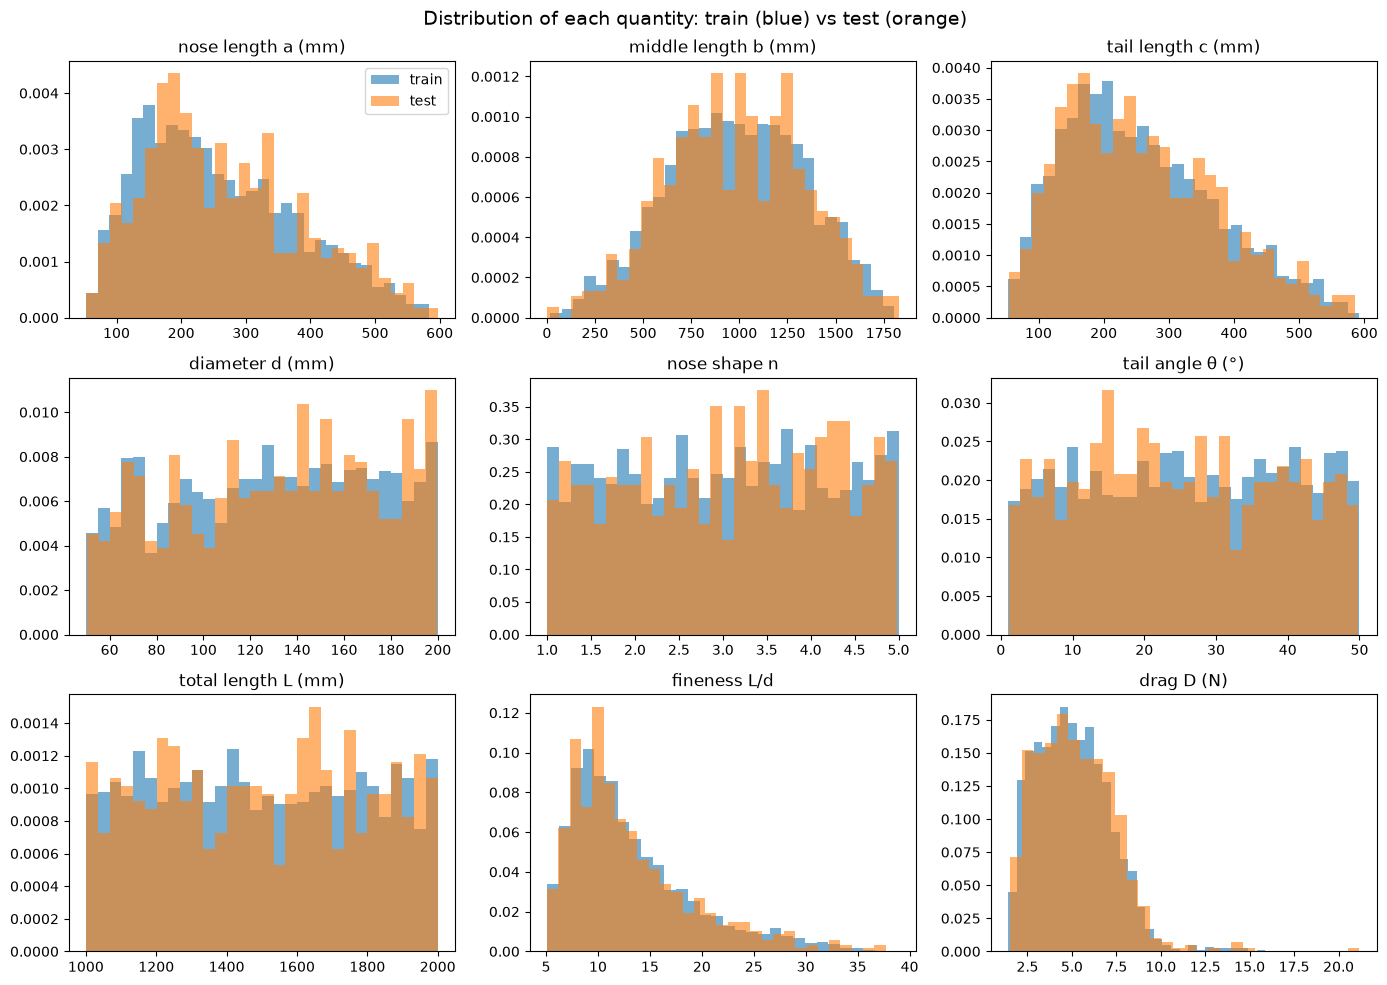

In [4]:
# matplotlib: the standard Python plotting library
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(14, 10))          # a 3 x 3 grid of small plots
for ax, (key, label) in zip(axes.ravel(), names.items()):
    ax.hist(tr[key], bins=30, alpha=0.6, density=True, label='train')
    ax.hist(te[key], bins=30, alpha=0.6, density=True, label='test')
    ax.set_title(label)
axes[0, 0].legend()
plt.suptitle('Distribution of each quantity: train (blue) vs test (orange)', fontsize=14)
plt.tight_layout()
plt.show()

### 1.6 The key question: how many *fat* hulls are there?
In the M0 analysis we found that **every model fails on fat hulls (L/d < 7)**. One simple explanation would be:
*there are just very few fat hulls to learn from.* Let's count them.

In [5]:
for label, data in [('train', tr), ('test', te)]:
    fat = data['Ld'] < 7
    print(f'{label:5s}: {fat.sum():4d} fat hulls (L/d < 7) out of {len(fat)}  →  {100 * fat.mean():.1f}%')

# How different is drag for fat hulls? Compare the median drag of fat vs slender hulls.
fat = tr['Ld'] < 7
print(f'\nMedian drag, fat hulls    : {np.median(tr["D"][fat]):.2f} N')
print(f'Median drag, slender hulls: {np.median(tr["D"][~fat]):.2f} N      (~ means "not")')

train:  217 fat hulls (L/d < 7) out of 2400  →  9.0%
test :   50 fat hulls (L/d < 7) out of 621  →  8.1%

Median drag, fat hulls    : 6.18 N
Median drag, slender hulls: 4.68 N      (~ means "not")


### 1.7 A 2D map of the design space
Histograms show one quantity at a time. A **scatter plot** of two quantities shows *combinations*.
Here: **fineness ratio (L/d)** against **diameter (d)**, each dot one hull, coloured by its drag.
The dashed line marks L/d = 7, the edge of the "fat hull" zone.

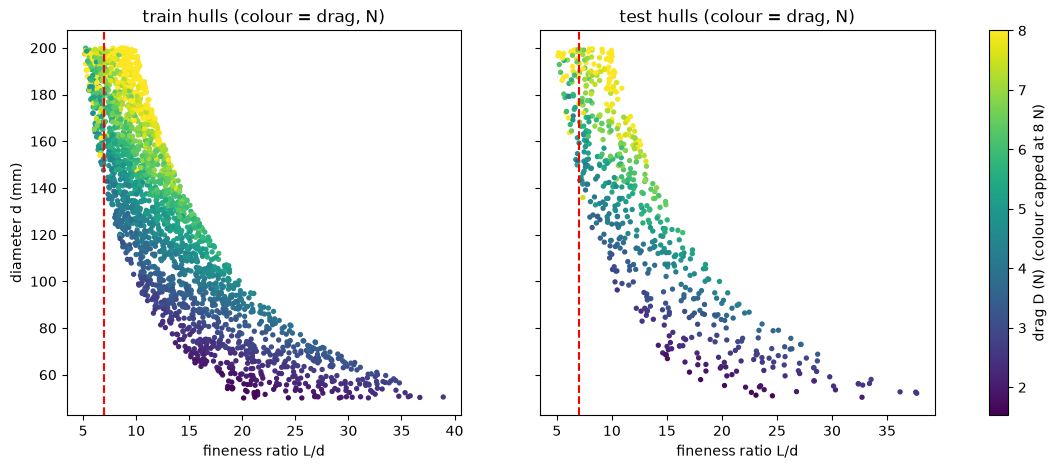

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for a_, (label, data) in zip(ax, [('train', tr), ('test', te)]):
    sc = a_.scatter(data['Ld'], data['d'], c=data['D'], s=8, cmap='viridis', vmax=8)
    a_.axvline(7, ls='--', c='red')                       # the fat-hull boundary
    a_.set(xlabel='fineness ratio L/d', title=f'{label} hulls (colour = drag, N)')
ax[0].set_ylabel('diameter d (mm)')
plt.colorbar(sc, ax=ax, label='drag D (N)  (colour capped at 8 N)')
plt.show()

### ✍️ Your turn — answer these from the outputs above (write your answers in a new Markdown cell below)
1. Do the train and test sets cover the **same ranges**? Any quantity where they differ?
2. What **percentage** of training hulls are fat (L/d < 7)? Is that *a lot* or *a little* for a model to learn from?
3. In the 2D map, **where** are the fat hulls — at large or small diameter? Why does that make geometric sense?
4. Which quantity has the most **uneven** (skewed) histogram? What could that mean for learning?

*When you are done, tell Claude your answers — then we move to Section 2 (drawing the hulls).*

SyntaxError: unmatched ')' (3693085361.py, line 2)

---
## Section 2 · Hull gallery — seeing the shapes

Numbers like "a = 253, d = 107, n = 3.1" are hard to picture. In this section we **draw** hulls from their six
numbers, so that words like *slender*, *fat*, *blunt nose* and *steep tail* become something you can see.

### 2.1 How a hull is drawn from six numbers
Our file `models/physics.py` contains `radius_profile(a, b, c, d, n, θ)`. It returns two arrays:
- `x`: positions along the hull, from the nose tip (x = 0) to the tail tip (x = L), in **metres**
- `r`: the hull's **radius** (half its thickness) at each position

The hull is round (a "body of revolution"), so if we plot `+r` and `-r` against `x` we get its **side view**.
The three parts use three formulas:
- **nose** (0 → a): a rounded curve; the exponent `n` controls how blunt it is
- **middle** (a → a + b): a straight cylinder of radius d/2
- **tail** (a + b → L): a cubic curve that closes the hull; θ sets how steep the very end is

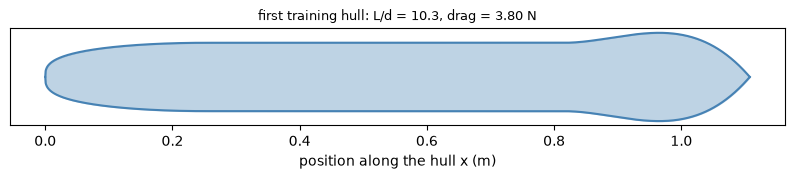

In [8]:
import sys
sys.path.insert(0, '..')                      # let Python find our 'models' folder one level up
from models.physics import radius_profile, drag_m0

def draw_hull(ax, row, title='', color='steelblue'):
    """Draw one hull's side view on the given plot axis. 'row' = one data row (a, b, c, d, n, θ, D)."""
    a, b, c, d, n, theta, D = row
    x, r = radius_profile(a, b, c, d, n, theta)
    ax.fill_between(x, -r, r, color=color, alpha=0.35)   # shade the body
    ax.plot(x, r, color=color); ax.plot(x, -r, color=color)
    ax.set_aspect('equal')                                # same scale on both axes = true shape
    ax.set_title(title, fontsize=9)
    ax.set_yticks([])

# Try it on the very first training hull
fig, ax = plt.subplots(figsize=(10, 2))
draw_hull(ax, train[0], title=f'first training hull: L/d = {tr["Ld"][0]:.1f}, drag = {train[0, 6]:.2f} N')
ax.set_xlabel('position along the hull x (m)')
plt.show()

### 2.2 Slender vs typical vs fat
We pick three hulls by their **fineness ratio L/d**: the most slender, one in the middle (median), and the fattest.

`np.argmax` / `np.argmin` return the **position** (row number) of the largest / smallest value;
`np.argsort` sorts and returns positions, so taking the middle one gives the median hull.

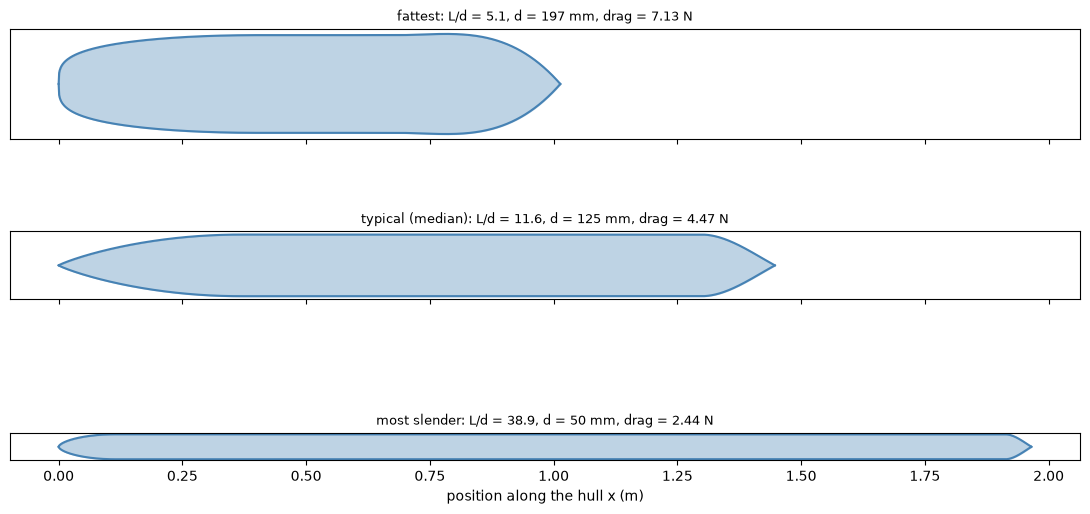

In [9]:
order = np.argsort(tr['Ld'])                   # row numbers sorted from fattest to most slender
picks = {'fattest': order[0], 'typical (median)': order[len(order) // 2], 'most slender': order[-1]}

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, (label, i) in zip(axes, picks.items()):
    draw_hull(ax, train[i], title=f'{label}: L/d = {tr["Ld"][i]:.1f}, d = {tr["d"][i]:.0f} mm, drag = {tr["D"][i]:.2f} N')
axes[-1].set_xlabel('position along the hull x (m)')
plt.tight_layout(); plt.show()

### 2.3 What do the nose exponent *n* and the tail angle θ change?
To see one parameter's effect, we keep everything else **fixed** and change only that parameter.
This is a basic scientific habit: *change one thing at a time*.

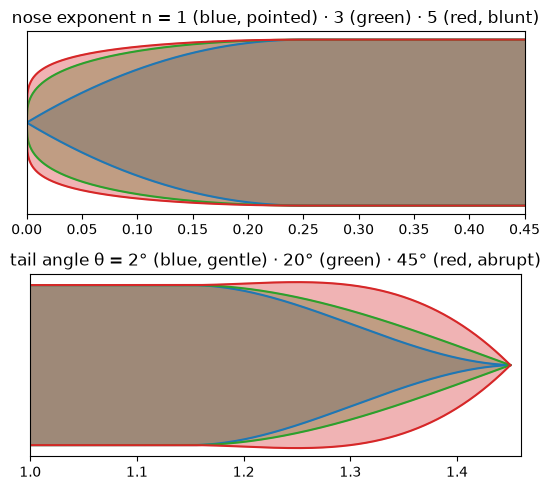

In [10]:
base = np.array([250, 900, 300, 150, 3.0, 20.0, 0.0])    # a, b, c, d, n, θ, (drag unused) — an invented hull

fig, axes = plt.subplots(2, 1, figsize=(11, 5))
for n_value, col in [(1.0, 'tab:blue'), (3.0, 'tab:green'), (5.0, 'tab:red')]:
    h = base.copy(); h[4] = n_value
    draw_hull(axes[0], h, color=col)
axes[0].set_title('nose exponent n = 1 (blue, pointed) · 3 (green) · 5 (red, blunt)')
axes[0].set_xlim(0, 0.45)                                 # zoom on the nose

for th_value, col in [(2, 'tab:blue'), (20, 'tab:green'), (45, 'tab:red')]:
    h = base.copy(); h[5] = th_value
    draw_hull(axes[1], h, color=col)
axes[1].set_title('tail angle θ = 2° (blue, gentle) · 20° (green) · 45° (red, abrupt)')
axes[1].set_xlim(1.0, 1.46)                               # zoom on the tail
plt.tight_layout(); plt.show()

### 2.4 The hulls where physics fails worst
In `phase1.ipynb` the physics model **M0** was badly wrong for a few hulls. Here we recompute M0 for every **test**
hull, find the 6 with the largest error, and draw them next to a typical well-predicted hull.

**Error (%)** = (M0 prediction − CFD drag) / CFD drag × 100. Negative = M0 predicts *too little* drag.

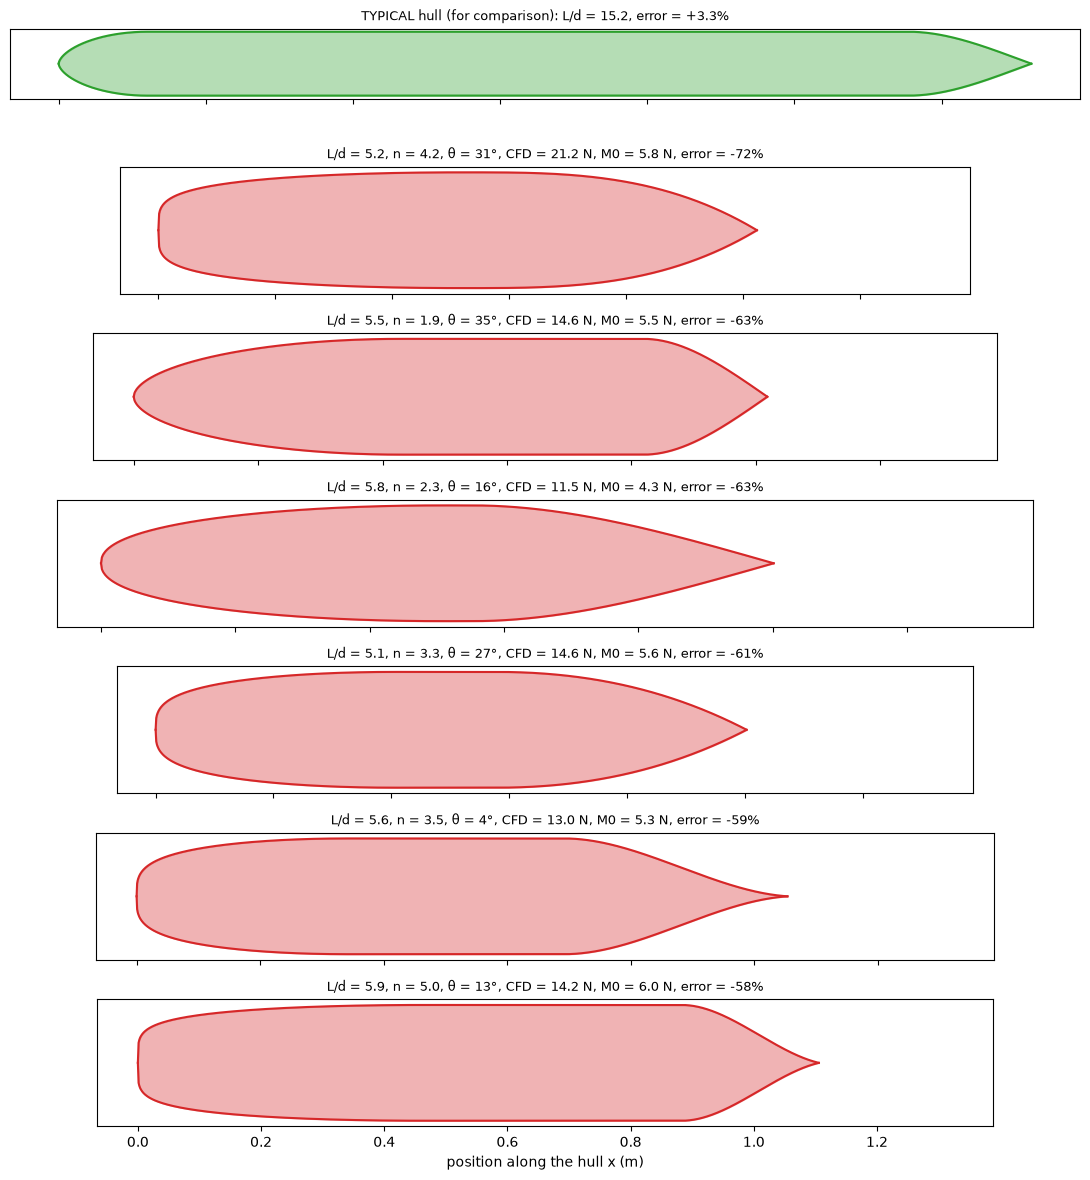

In [11]:
m0 = np.array([drag_m0(*row[:6]) for row in test])          # physics prediction for each test hull
err = (m0 - te['D']) / te['D'] * 100
worst = np.argsort(-np.abs(err))[:6]                          # the 6 largest absolute errors
good = np.argsort(np.abs(err))[len(err) // 2]                 # a hull with a typical (median) error

fig, axes = plt.subplots(7, 1, figsize=(11, 12), sharex=True)
draw_hull(axes[0], test[good], color='tab:green',
          title=f'TYPICAL hull (for comparison): L/d = {te["Ld"][good]:.1f}, error = {err[good]:+.1f}%')
for ax, i in zip(axes[1:], worst):
    draw_hull(ax, test[i], color='tab:red',
              title=f'L/d = {te["Ld"][i]:.1f}, n = {te["n"][i]:.1f}, θ = {te["theta"][i]:.0f}°, '
                    f'CFD = {te["D"][i]:.1f} N, M0 = {m0[i]:.1f} N, error = {err[i]:+.0f}%')
axes[-1].set_xlabel('position along the hull x (m)')
plt.tight_layout(); plt.show()

### ✍️ Your turn
1. Looking at **2.2**: describe the fattest hull in everyday words. What would water have to do to flow around its back end?
2. Looking at **2.3**: which parameter changes the shape **more visibly**, *n* or θ? Is θ's effect big or small?
3. Looking at **2.4**: what do the 6 failure hulls have **in common**? Is it the nose, the middle, or the tail?
4. A bonus thought: the failures are **all under-predictions** (M0 too low). What *extra* drag exists in reality that a
   friction formula would miss?

*Tell Claude your answers, then we move to Section 3 (the physics view).*